# LLM Fine Tuning · Lesson 6 · Tool calls for agents

Lessons 1 to 5 taught one model one task: a question about a table in, one SQLite query out. This lab changes the
task, because tool calling is a different kind of output. The model is given a few function definitions and a
request, and must either write **one call** that a program can run, or **write no call** when the request needs
no tool. Qwen2.5-1.5B-Instruct is used again, with its own tool-calling chat template.

What makes this task special is that a program, not a person, can say whether the output is right. So the lab builds
that program first, and everything else is measured with it.

Seven questions are asked, each answered by a measurement:

1. **What data teaches tool calls, and is it clean?** A public function-calling set, parsed and filtered.
2. **How does a program decide that a call is right?** A four-stage checker, tested on hand-written outputs.
3. **How do we keep the test tools unseen?** A split by function, with no function in both train and test.
4. **How good is the model before any training?** Zero-shot, with the tools in the chat template.
5. **How do we train it?** LoRA SFT exactly as in lesson 4, with the loss on the answer only.
6. **What changed?** The same 500 test examples, scored by the same checker.
7. **What is still wrong?** The failures, sorted by the stage at which they fail.

**Run it:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all. It takes about 40 minutes on a T4:
about 5 minutes of data preparation, 6 of generation (two passes) and 20 to 30 of training.
The lesson that explains every result is at [docs.recohut.com](https://docs.recohut.com/courses/llm-fine-tuning/2-train/06-tool-calls).

## 0. Install and import

In [1]:
# Pinned versions, so the code matches the lesson it was written for.
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 trl==0.19.1 datasets==3.6.0 jsonschema==4.23.0

pip may report dependency conflicts with packages Colab preinstalls, such as `gradio`. This lab does not use them,
so the warning can be ignored. `jsonschema` is the one new package: it is the standard Python validator for JSON
Schema, which is the language function definitions are written in.

In [2]:
import gc
import hashlib
import json
import os
import random
import re
import time
import urllib.request
from collections import Counter
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import trl
from datasets import Dataset
from jsonschema import Draft202012Validator
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

%config InlineBackend.figure_formats = ['svg']
assert torch.cuda.is_available(), "Choose Runtime -> Change runtime type -> T4 GPU."

SEED = 42
set_seed(SEED)
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
DEVICE = "cuda"
DTYPE = torch.float16        # a T4 has no bfloat16 (lesson 2)
GB = 1e9

# Size knobs: how many examples of each kind. "call" examples must end in a call; the other three must not.
TEST_MIX = {"call": 300, "missing value": 80, "no fit": 60, "unrelated tools": 60}        # 500 test examples
TRAIN_MIX = {"call": 2200, "missing value": 800, "no fit": 200, "unrelated tools": 800}   # 4,000 training examples
VAL_MIX = {"call": 100, "missing value": 50, "unrelated tools": 50}                       # 200, for the loss curve only
MAX_TOKENS = 512             # longest prompt + answer kept (examples above it are skipped, and counted)
MAX_REPLY = 160              # longest plain-text answer kept, so the training answers are never cut short
N_TEST, N_TRAIN, N_VAL = sum(TEST_MIX.values()), sum(TRAIN_MIX.values()), sum(VAL_MIX.values())
RAW_PATH = "glaive.json"
CHECK_TEMPLATE = True        # section 3 asserts that Qwen's own chat template renders our target exactly
print("transformers", transformers.__version__, "| trl", trl.__version__, "| peft", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0))
tok = AutoTokenizer.from_pretrained(MODEL_ID, padding_side="left")

transformers 4.51.3 | trl 0.19.1 | peft 0.15.2
GPU: Tesla T4


## 1. What data teaches tool calls, and is it clean?

The data is **glaive-function-calling-v2**, about 113,000 chat transcripts from Glaive AI (Apache 2.0, ungated). Each
has a system message that lists one or two function definitions (or says there are none), then a conversation in
which the assistant sometimes answers with a `<functioncall>`. The file is pinned to one commit below.

It is the right raw material for three reasons, and an awkward format in one respect:

- the function definitions are JSON Schema, so a program can validate an argument without a person;
- many conversations end without a call, so **not calling** can be taught and tested too: the request may need a
  value the user did not give, or no listed function fits it;
- some listed functions are unrelated to the request, which is the real danger: a model that always calls something.

The awkward part: the call is written in a home-made form (`"arguments": '{...}'`, the arguments as a quoted string),
so each target has to be parsed, and some do not parse.

This lab uses only the **first assistant reply** to the first user message, and only replies that are either
exactly one call or no call at all. That is a deliberate narrowing, stated here so nobody reads the results as
covering several calls in a row or a conversation with tool results.

Cleaning rules, each with its count printed below: the function list must be valid JSON Schema with unique names;
the target must be valid JSON; the called function must be one of the listed ones; and the **target's own arguments
must pass the same checker** the model will be scored with. A gold answer that fails its own checker would punish
a correct model.

In [3]:
DATA_URL = ("https://huggingface.co/datasets/glaiveai/glaive-function-calling-v2/resolve/"
            "e7f4b6456019f5d8bcb991ef0dd67d8ff23221ac/glaive-function-calling-v2.json")
if not os.path.exists(RAW_PATH):
    urllib.request.urlretrieve(DATA_URL, RAW_PATH)
raw = json.load(open(RAW_PATH))
print(f"{len(raw):,} conversations;", "first system message:", raw[0]["system"][:90].replace("\n", " "), "...")

ROLE = re.compile(r"(?m)^(USER|ASSISTANT|FUNCTION RESPONSE): ")
# Glaive writes a call as:  <functioncall> {"name": "f", "arguments": '{"a": 1}'}   (arguments as a quoted string)
CALL = re.compile(r"<functioncall>\s*\{\s*\"name\":\s*\"([^\"]+)\",\s*\"arguments\":\s*(?:'(.*)'|\"(.*)\"|(\{.*\}))\s*\}\s*", re.S)


def turns(chat):
    """Split a transcript into (role, text) turns."""
    marks = list(ROLE.finditer(chat))
    return [(m.group(1), chat[m.end():(marks[i + 1].start() if i + 1 < len(marks) else len(chat))]
             .replace("<|endoftext|>", "").strip()) for i, m in enumerate(marks)]


def parse_tools(system):
    """The function definitions listed in the system message ([] when there are none)."""
    if "no access to external functions" in system[:150]:
        return []
    body, i, found, decoder = system.split("Use them if required -", 1)[1], 0, [], json.JSONDecoder()
    while True:
        while i < len(body) and body[i].isspace():
            i += 1
        if i >= len(body):
            return found
        obj, i = decoder.raw_decode(body, i)
        found.append(obj)


funnel = [("conversations in the file", 0, len(raw))]


def keep(rows_, label, test):
    """Keep the rows where test(row) is true, and record how many were dropped for this reason."""
    kept = [r for r in rows_ if test(r)]
    funnel.append((label, len(rows_) - len(kept), len(kept)))
    return kept


rows = []
for i, e in enumerate(raw):
    t = turns(e["chat"])
    try:
        tools = parse_tools(e["system"])
    except (ValueError, IndexError):
        rows.append({"id": i, "status": "function list not parseable"})
        continue
    first_reply = []
    for role, text in t[1:]:
        if role != "ASSISTANT":
            break
        first_reply.append(text)
    status = "ok" if t and t[0][0] == "USER" and len(first_reply) == 1 else "reply spans several turns"
    rows.append({"id": i, "status": status, "user": t[0][1] if t else "", "tools": tools,
                 "reply": first_reply[0] if first_reply else ""})
rows = keep(rows, "reply not a single assistant turn, or function list not parseable", lambda r: r["status"] == "ok")

112,960 conversations; first system message: SYSTEM: You are a helpful assistant with access to the following functions. Use them if re ...


In [4]:
@lru_cache(maxsize=None)
def validator(schema_json):
    return Draft202012Validator(json.loads(schema_json))


def argument_errors(args, function):
    """Why `args` breaks the function's JSON Schema. An empty list means valid.
    Beyond the schema itself, an argument the function does not declare counts as an error ("invented argument")."""
    schema = function.get("parameters") or {"type": "object"}
    errors = [e.validator for e in validator(json.dumps(schema, sort_keys=True)).iter_errors(args)]
    errors += ["extra argument" for k in args if k not in schema.get("properties", {})]
    return errors


def tool_schema_ok(t):
    """A function definition is usable if it has a name, only the expected keys, and a valid JSON Schema."""
    try:
        if not isinstance(t.get("name"), str) or set(t) - {"name", "description", "parameters", "required"}:
            return False
        Draft202012Validator.check_schema(t.get("parameters") or {"type": "object"})
        return True
    except Exception:
        return False


def clean_tools(r):
    names = [t.get("name") for t in r["tools"]]
    if not all(tool_schema_ok(t) for t in r["tools"]) or len(set(names)) != len(names):
        return None
    # chat templates expect {"type": "function", "function": {...}}; a stray top-level "required" key is dropped
    return [{"type": "function", "function": {k: v for k, v in t.items() if k != "required"}} for t in r["tools"]]


for r in rows:
    r["tools"] = clean_tools(r)
rows = keep(rows, "function list is not valid JSON Schema, or repeats a name", lambda r: r["tools"] is not None)


def parse_reply(r):
    """Fill r['gold'] with {"name", "arguments"} for a call, or None for a reply with no call. Return a drop reason or ''."""
    if "<functioncall>" not in r["reply"]:
        r["gold"] = None
        return ""
    if not r["reply"].startswith("<functioncall>"):
        return "text before the call"
    m = CALL.fullmatch(r["reply"])
    if not m:
        return "not exactly one call in the expected form"
    try:
        args = json.loads(next(g for g in m.groups()[1:] if g is not None))
    except ValueError:
        return "target arguments are not valid JSON"
    if not isinstance(args, dict):
        return "target arguments are not an object"
    if m.group(1) not in [t["function"]["name"] for t in r["tools"]]:
        return "called function is not one of the listed ones"
    r["gold"] = {"name": m.group(1), "arguments": args}
    return ""


for r in rows:
    r["status"] = parse_reply(r)
for reason in ["text before the call", "not exactly one call in the expected form", "target arguments are not valid JSON",
               "target arguments are not an object", "called function is not one of the listed ones"]:
    rows = keep(rows, reason, lambda r, reason=reason: r["status"] != reason)


def gold_valid(r):
    if r["gold"] is None:
        return True
    fn = next(t["function"] for t in r["tools"] if t["function"]["name"] == r["gold"]["name"])
    return not argument_errors(r["gold"]["arguments"], fn)


rows = keep(rows, "target arguments fail the function's own schema", gold_valid)
for r in rows:
    r["norm"] = re.sub(r"\s+", " ", r["user"].strip().lower())
seen, unique = set(), []
for r in rows:
    key = (r["norm"], tuple(sorted(t["function"]["name"] for t in r["tools"])),
           json.dumps(r["gold"], sort_keys=True) if r["gold"] else r["reply"][:60])
    if key not in seen:
        seen.add(key)
        unique.append(r)
funnel.append(("exact duplicates (same request, functions and answer)", len(rows) - len(unique), len(unique)))
rows = unique

print(pd.DataFrame(funnel, columns=["step", "dropped", "left"]).to_string(index=False))
print("\ncalls:", sum(r["gold"] is not None for r in rows), "| replies with no call:", sum(r["gold"] is None for r in rows))

                                                             step  dropped   left
                                        conversations in the file        0 112960
reply not a single assistant turn, or function list not parseable     7826 105134
        function list is not valid JSON Schema, or repeats a name      368 104766
                                             text before the call        2 104764
                        not exactly one call in the expected form        5 104759
                              target arguments are not valid JSON        5 104754
                               target arguments are not an object        0 104754
                    called function is not one of the listed ones        0 104754
                  target arguments fail the function's own schema      376 104378
            exact duplicates (same request, functions and answer)    44291  60087

calls: 14621 | replies with no call: 45466


### What kinds of answer are in the data?

Every example now has a listed set of functions and a target that is one call or no call. The no-call replies come in
three kinds, which the lab keeps apart because a model can fail them differently. The kind is read from the target
text with simple rules, so it is a label made by this notebook, not by the dataset:

- **missing value:** the reply asks the user for something ("Could you please provide ..."): a required value was not given;
- **no fit:** the reply apologises ("I'm sorry, I can't book flights ..."): no listed function does what was asked;
- **unrelated tools:** a plain chat request with no functions in the original data (an essay, a riddle, a recipe). The
  notebook adds one or two functions picked at random from the same side of the split, skipping any whose name shares a
  word with the request. The right answer is still the original plain-text reply, but now the model must resist
  a tool that is on offer.

In [5]:
def kind_of(r):
    if r["gold"] is not None:
        return "call"
    if not r["tools"]:
        return "chat"                       # becomes "unrelated tools" once functions are added below
    t = r["reply"].lower()
    if re.search(r"sorry|unable|cannot|can't|don't have|do not have|not able|no function|not capable", t):
        return "no fit"
    if "?" in t or "please provide" in t:
        return "missing value"
    return "other"


for r in rows:
    r["kind"] = kind_of(r)
print(pd.Series(Counter(r["kind"] for r in rows)).rename("examples").to_string())
print("\nexample of each kind:")
for k in ["call", "missing value", "no fit", "chat"]:
    r = next(r for r in rows if r["kind"] == k)
    print(f"[{k}] user: {r['user'][:110]!r}\n      functions: {[t['function']['name'] for t in r['tools']]}"
          f"\n      target: {(json.dumps(r['gold']) if r['gold'] else r['reply'])[:130]!r}")

no fit            4607
call             14621
missing value     5956
chat             34565
other              338

example of each kind:
[call] user: 'Can you tell me the latest news headlines for the United States?'
      functions: ['get_news_headlines']
      target: '{"name": "get_news_headlines", "arguments": {"country": "United States"}}'
[missing value] user: 'I need a new password. Can you generate one for me?'
      functions: ['generate_password', 'create_task']
      target: 'Of course. How long would you like your password to be? And would you like it to include symbols?'
[no fit] user: 'Can you book a flight for me from New York to London?'
      functions: ['get_exchange_rate']
      target: "I'm sorry, but I don't have the capability to book flights. My current function allows me to get the exchange rate between two cur"
[chat] user: 'You are given a sequence of numbers: 2, 4, 6, 8, 10. Each number represents a moment in time, just like the wa'
      functions: []
     

## 2. How does a program decide that a call is right?

This is the core idea of the lesson. A tool call can be wrong in four separate ways, and each one is something a
program can test without asking a person:

1. **parse:** the output is exactly one `<tool_call>` block holding a JSON object with `name` and `arguments`
   (an object), and nothing else. If this fails, nothing downstream can run it.
2. **name:** the function exists in the list the model was given, and it is the one the request needs.
3. **schema:** the arguments are valid JSON Schema for that function: required ones present, types right, values
   inside any `enum`, and no argument the function does not declare.
4. **exact:** the arguments equal the gold arguments. Strict: `1` and `true` differ; `Paris` and `paris` differ.

The stages are cumulative. A call is counted at a stage only if it passed all earlier ones, so the pass rates fall
from stage to stage, and the stage where they fall most is where the model is weak. **Exact is the only stage
that needs a gold answer;** the other three need only the function list, so they could run on live traffic.

For a request that needs **no call**, the right output is the absence of one: no `<tool_call>` tag and a
non-empty reply. Calling a function anyway is the failure.

A checker is code, and code has bugs, so it is tested before it is trusted: 15 hand-written outputs, each with the
result it must get. The asserts below fail the notebook if the checker disagrees.

In [6]:
CALL_BLOCK = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.S)
SCHEMA_LABELS = [("required", "missing required argument"), ("type", "wrong argument type"),
                 ("enum", "value outside the allowed list"), ("extra argument", "invented argument")]


def strict_equal(a, b):
    """JSON equality that keeps booleans apart from numbers (Python says True == 1; JSON does not)."""
    if isinstance(a, bool) or isinstance(b, bool):
        return type(a) is type(b) and a == b
    if isinstance(a, (int, float)) and isinstance(b, (int, float)):
        return a == b
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(strict_equal(a[k], b[k]) for k in a)
    if isinstance(a, list) and isinstance(b, list):
        return len(a) == len(b) and all(strict_equal(x, y) for x, y in zip(a, b))
    return type(a) is type(b) and a == b


def check(output, tools, gold):
    """Score one model output. `gold` is {"name", "arguments"} for a call, or None when no call is right.
    Returns the four stage flags (cumulative), `ok` (the whole example passed) and `failure` (the first stage that failed)."""
    text = output.strip()
    res = {"parse": False, "name": False, "schema": False, "exact": False, "ok": False, "failure": ""}
    if gold is None:                                   # the right output makes no call
        called = "<tool_call>" in text or "<functioncall>" in text
        res["failure"] = "called a function" if called else ("empty reply" if not text else "")
        res["parse"] = res["ok"] = res["failure"] == ""
        return res

    def fail(why):
        res["failure"] = why
        return res

    blocks = CALL_BLOCK.findall(text)
    if "<tool_call>" not in text:
        return fail("no call (answered in text)")
    if not blocks:
        return fail("unclosed <tool_call> tag")
    if len(blocks) > 1:
        return fail("several calls")
    if CALL_BLOCK.sub("", text).strip():
        return fail("text around the call")
    try:
        call = json.loads(blocks[0])
    except ValueError:
        return fail("invalid JSON")
    if not isinstance(call, dict) or set(call) != {"name", "arguments"}:
        return fail("wrong keys")
    if not isinstance(call["arguments"], dict):
        return fail("arguments not an object")
    res["parse"] = True

    offered = {t["function"]["name"]: t["function"] for t in tools}
    if not isinstance(call["name"], str) or call["name"] not in offered:
        return fail("function not offered (invented name)")
    if call["name"] != gold["name"]:
        return fail("wrong function")
    res["name"] = True

    errors = set(argument_errors(call["arguments"], offered[call["name"]]))
    if errors:
        return fail(next((label for key, label in SCHEMA_LABELS if key in errors), "other schema error"))
    res["schema"] = True

    if not strict_equal(call["arguments"], gold["arguments"]):
        return fail("valid arguments, wrong value")
    res["exact"] = res["ok"] = True
    return res

In [7]:
# Two functions and one request, "weather in Paris in celsius", so each failure mode has a hand-written example.
T = [{"type": "function", "function": {"name": "get_weather", "description": "Current weather", "parameters": {
         "type": "object", "properties": {"city": {"type": "string"}, "unit": {"type": "string", "enum": ["celsius", "fahrenheit"]}},
         "required": ["city"]}}},
     {"type": "function", "function": {"name": "get_time", "description": "Time in a zone", "parameters": {
         "type": "object", "properties": {"zone": {"type": "string"}}, "required": ["zone"]}}}]
GOLD = {"name": "get_weather", "arguments": {"city": "Paris", "unit": "celsius"}}


def call_text(name, args):
    return "<tool_call>\n" + json.dumps({"name": name, "arguments": args}) + "\n</tool_call>"


good = call_text("get_weather", {"city": "Paris", "unit": "celsius"})
# (label, output, gold, expected = parse, name, schema, exact)
hand = [
    ("exactly right", good, GOLD, (1, 1, 1, 1)),
    ("same call, keys in another order", call_text("get_weather", {"unit": "celsius", "city": "Paris"}), GOLD, (1, 1, 1, 1)),
    ("answers in prose", "It is mild in Paris today.", GOLD, (0, 0, 0, 0)),
    ("call plus a sentence", "Sure!\n" + good, GOLD, (0, 0, 0, 0)),
    ("trailing comma", '<tool_call>\n{"name": "get_weather", "arguments": {"city": "Paris",}}\n</tool_call>', GOLD, (0, 0, 0, 0)),
    ("tag never closed", '<tool_call>\n{"name": "get_weather", "arguments": {"city": "Paris"}}', GOLD, (0, 0, 0, 0)),
    ("two calls", good + "\n" + good, GOLD, (0, 0, 0, 0)),
    ("arguments is a string", '<tool_call>\n{"name": "get_weather", "arguments": "Paris"}\n</tool_call>', GOLD, (0, 0, 0, 0)),
    ("invented function name", call_text("get_wether", {"city": "Paris"}), GOLD, (1, 0, 0, 0)),
    ("the other listed function", call_text("get_time", {"zone": "CET"}), GOLD, (1, 0, 0, 0)),
    ("required argument missing", call_text("get_weather", {"unit": "celsius"}), GOLD, (1, 1, 0, 0)),
    ("wrong type (city is a number)", call_text("get_weather", {"city": 75001}), GOLD, (1, 1, 0, 0)),
    ("value outside the enum", call_text("get_weather", {"city": "Paris", "unit": "kelvin"}), GOLD, (1, 1, 0, 0)),
    ("argument the function lacks", call_text("get_weather", {"city": "Paris", "unit": "celsius", "country": "FR"}), GOLD, (1, 1, 0, 0)),
    ("valid but not the gold value", call_text("get_weather", {"city": "paris", "unit": "celsius"}), GOLD, (1, 1, 1, 0)),
]
table = []
for label, output, gold, expected in hand:
    res = check(output, T, gold)
    got = tuple(int(res[s]) for s in ["parse", "name", "schema", "exact"])
    assert got == expected, (label, got, expected, res["failure"])
    table.append({"output": label, "parse": got[0], "name": got[1], "schema": got[2], "exact": got[3],
                  "first failure": res["failure"] or "-"})
print(pd.DataFrame(table).to_string(index=False))

# No call is right: prose passes, any call fails.
assert check("I can only tell you the weather or the time.", T, None)["ok"]
assert check(good, T, None)["failure"] == "called a function"
assert not check("", T, None)["ok"]
assert strict_equal({"a": 1}, {"a": 1.0}) and not strict_equal(True, 1) and not strict_equal({"a": [1, 2]}, {"a": [2, 1]})
print("\nchecker asserts passed: 15 call outputs, 3 no-call outputs, strict_equal")

                          output  parse  name  schema  exact                        first failure
                   exactly right      1     1       1      1                                    -
same call, keys in another order      1     1       1      1                                    -
                answers in prose      0     0       0      0           no call (answered in text)
            call plus a sentence      0     0       0      0                 text around the call
                  trailing comma      0     0       0      0                         invalid JSON
                tag never closed      0     0       0      0             unclosed <tool_call> tag
                       two calls      0     0       0      0                        several calls
           arguments is a string      0     0       0      0              arguments not an object
          invented function name      1     0       0      0 function not offered (invented name)
       the other lis

Notice the row "same call, keys in another order": it passes, because the checker compares parsed JSON, not text.
That is the reason a program-checked task is more forgiving than lesson 3's exact string match, and also stricter
where it matters: `"city": 75001` is rejected before it reaches any API.

## 3. How do we keep the test tools unseen?

Lesson 3 split by table because a model that has seen a table in training can recite its queries. The same trap
exists here, and it is worse: this data has about 1,000 function names, and a few (`calculate_bmi`, `calculate_age`,
`convert_currency`) appear thousands of times. A random split would test almost only functions seen in training.

The rule: **each function name is assigned to one side by a hash of its name:** 15% test, 5% validation, 80% train. An
example belongs to the side of the functions it lists, and an example that lists functions from two sides is dropped.
So no function the model is tested on, called or offered, appeared in training. Chat requests with no functions are
placed by a hash of their text. Two more rules against leaks: at most two examples per request text, and a request text
found in the test side is removed from training.

What this does *not* stop: two differently named functions that do the same thing (a `compute_bmi` in train and a
`calculate_bmi` in test). Names are the unit used here; semantic duplicates would need an embedding check.

In [8]:
def side_of(key):
    h = int(hashlib.md5(f"{SEED}:{key}".encode()).hexdigest(), 16) % 100
    return "test" if h < 15 else "validation" if h < 20 else "train"


def side_for(r):
    sides = {side_of("fn:" + t["function"]["name"]) for t in r["tools"]} if r["tools"] else {side_of("user:" + r["norm"])}
    return sides.pop() if len(sides) == 1 else "straddles sides"


for r in rows:
    r["side"] = side_for(r)
print("before dropping:", dict(Counter(r["side"] for r in rows)))
rows = keep(rows, "lists functions from more than one side of the split", lambda r: r["side"] != "straddles sides")

random.Random(SEED).shuffle(rows)
per_text, capped = Counter(), []
for r in rows:
    per_text[(r["side"], r["norm"])] += 1
    if per_text[(r["side"], r["norm"])] <= 2:
        capped.append(r)
funnel.append(("more than two examples with the same request text", len(rows) - len(capped), len(capped)))
test_texts = {r["norm"] for r in capped if r["side"] == "test"}
rows = keep(capped, "train or validation request text also on the test side", lambda r: r["side"] == "test" or r["norm"] not in test_texts)

print(pd.DataFrame(funnel[-4:], columns=["step", "dropped", "left"]).to_string(index=False))
pools = {}
for r in rows:
    pools.setdefault((r["side"], r["kind"]), []).append(r)
print("\npool sizes (side, kind):")
print(pd.Series({f"{s} / {k}": len(v) for (s, k), v in sorted(pools.items())}).to_string())
# Functions available for the 'unrelated tools' kind, by side of the split (first definition seen for each name).
fn_pool = {s: {} for s in ["train", "validation", "test"]}
for r in rows:
    for t in r["tools"]:
        fn_pool[r["side"]].setdefault(t["function"]["name"], t)
print("distinct functions per side:", {s: len(f) for s, f in fn_pool.items()})

before dropping: {'train': 48019, 'straddles sides': 2846, 'validation': 2358, 'test': 6864}
                                                  step  dropped  left
 exact duplicates (same request, functions and answer)    44291 60087
  lists functions from more than one side of the split     2846 57241
     more than two examples with the same request text    11737 45504
train or validation request text also on the test side      347 45157

pool sizes (side, kind):
test / call                     677
test / chat                    5216
test / missing value            234
test / no fit                    98
test / other                     10
train / call                   6646
train / chat                  27553
train / missing value          2215
train / no fit                  219
train / other                   204
validation / call               153
validation / chat              1796
validation / missing value      124
validation / no fit               9
validation / other         

distinct functions per side: {'train': 711, 'validation': 33, 'test': 111}


Now the prompts. Qwen2.5's chat template has a native tool-calling form: pass the function list as `tools=`, and
the template writes a `# Tools` section into the system message and tells the model to answer with
`<tool_call>{"name": ..., "arguments": ...}</tool_call>`. The model was trained on that form, so the fine-tune
teaches it *when* and *how correctly*, not a new syntax. The system line is the same for every system in this lab:
it says to call only when the request needs it and every required value is given, which is the rule the targets follow.
That makes the untuned baseline a fair one: the instruction is in the prompt.

Each sampled example is turned into two strings: the **prompt** (rendered by the template, ending with the assistant
header) and the **completion** (the target). The cell asserts that for calls the completion is *exactly* what the
template itself would write for an assistant message with `tool_calls`.

In [9]:
SYSTEM = ("You are a helpful assistant. Call a provided function only when the request needs it and every required value "
          "is stated in the conversation; otherwise reply in plain text and do not guess values.")


def build_prompt(r):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": r["user"]}]
    return tok.apply_chat_template(messages, tools=r["tools"], tokenize=False, add_generation_prompt=True)


def target_text(r):
    if r["gold"] is None:
        return r["reply"]
    return "<tool_call>\n" + json.dumps({"name": r["gold"]["name"], "arguments": r["gold"]["arguments"]}, ensure_ascii=False) + "\n</tool_call>"


def words(name):
    return [w for w in name.lower().split("_") if len(w) > 3]


def with_unrelated_tools(r, side):
    """Offer one or two functions from the same side of the split to a chat request, skipping any that share a word with it."""
    rng = random.Random(f"{SEED}:{r['id']}")
    names = sorted(fn_pool[side])
    for _ in range(10):
        picked = rng.sample(names, rng.choice([1, 1, 2]))
        if not any(w in r["norm"] for n in picked for w in words(n)):
            return dict(r, tools=[fn_pool[side][n] for n in picked], kind="unrelated tools")
    return None


skipped = Counter()


def take(side, kind, n):
    """n examples of one kind from one side of the split, with prompt, completion and token count filled in."""
    rng = random.Random(f"{SEED}:{side}:{kind}")
    candidates = list(pools[(side, "chat" if kind == "unrelated tools" else kind)])
    rng.shuffle(candidates)
    out = []
    for r in candidates:
        if len(out) == n:
            break
        if kind == "unrelated tools":
            r = with_unrelated_tools(r, side)
            if r is None:
                continue
        prompt, completion = build_prompt(r), target_text(r)
        n_prompt, n_completion = len(tok(prompt).input_ids), len(tok(completion).input_ids) + 1   # +1: the end-of-turn token
        if n_prompt + n_completion > MAX_TOKENS or (kind != "call" and n_completion > MAX_REPLY):
            skipped[(side, kind)] += 1
            continue
        out.append(dict(r, prompt=prompt, completion=completion, n_tokens=n_prompt + n_completion))
    assert len(out) == n, f"only {len(out)} of {n} {kind!r} examples available on the {side} side"
    return out


test = [r for k, n in TEST_MIX.items() for r in take("test", k, n)]
val = [r for k, n in VAL_MIX.items() for r in take("validation", k, n)]
train = [r for k, n in TRAIN_MIX.items() for r in take("train", k, n)]
random.Random(SEED).shuffle(test)
random.Random(SEED).shuffle(train)
print("skipped for length (side, kind):", dict(skipped))

fns = lambda rs: {t["function"]["name"] for r in rs for t in r["tools"]}
assert not fns(train) & fns(test) and not fns(val) & fns(test) and not fns(train) & fns(val), "a function is on two sides"
assert not {r["norm"] for r in train} & {r["norm"] for r in test}, "a request text is on both sides"
print(f"\nno function and no request text is on both sides of the split")
print(pd.DataFrame({name: pd.Series(Counter(r["kind"] for r in rs)) for name, rs in
                    [("train", train), ("validation", val), ("test", test)]}).fillna(0).astype(int).to_string())
print("\ndistinct functions:", {n: len(fns(rs)) for n, rs in [("train", train), ("validation", val), ("test", test)]})
print("distinct request texts in the test set:", {k: len({r["norm"] for r in test if r["kind"] == k}) for k in TEST_MIX})
print(f"mean tokens per training example: {np.mean([r['n_tokens'] for r in train]):.0f} (prompt and answer), longest {max(r['n_tokens'] for r in train)}")

if CHECK_TEMPLATE:
    for r in [r for r in train if r["gold"]][:25]:
        messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": r["user"]},
                    {"role": "assistant", "content": "", "tool_calls": [{"type": "function", "function": r["gold"]}]}]
        assert tok.apply_chat_template(messages, tools=r["tools"], tokenize=False) == r["prompt"] + r["completion"] + "<|im_end|>\n"
    print("template check passed: for 25 calls, prompt + completion + <|im_end|> is exactly what the chat template writes")
ex = next(r for r in train if r["gold"])
print("\n--- one training prompt, as the model sees it ---\n" + ex["prompt"] + "\n--- and its completion ---\n" + ex["completion"])

skipped for length (side, kind): {('test', 'call'): 1, ('test', 'unrelated tools'): 120, ('validation', 'unrelated tools'): 91, ('train', 'call'): 21, ('train', 'unrelated tools'): 1648}

no function and no request text is on both sides of the split
                 train  validation  test
call              2200         100   300
missing value      800          50    80
no fit             200           0    60
unrelated tools    800          50    60

distinct functions: {'train': 646, 'validation': 32, 'test': 89}
distinct request texts in the test set: {'call': 283, 'missing value': 74, 'no fit': 49, 'unrelated tools': 60}
mean tokens per training example: 320 (prompt and answer), longest 512
template check passed: for 25 calls, prompt + completion + <|im_end|> is exactly what the chat template writes

--- one training prompt, as the model sees it ---
<|im_start|>system
You are a helpful assistant. Call a provided function only when the request needs it and every required value is st

## 4. How good is the model before any training?

Qwen2.5-1.5B-Instruct was trained on tool calling, so the baseline is a real model with a real chance: the
function list is in its template, the instruction is in the prompt, and decoding is greedy so the numbers can be
reproduced. The same checker scores it on the same 500 test examples. **Call examples** are scored through the
four stages; **no-call examples** pass when the output contains no call.

In [10]:
@torch.inference_mode()
def generate(model, prompts, batch=16, max_new_tokens=160):
    """Greedy answers for a list of rendered prompts, batched with left padding. Returns (answers, ms per example)."""
    model.generation_config.update(temperature=None, top_p=None, top_k=None)

    def run(chunk, n_new):
        enc = tok(chunk, return_tensors="pt", padding=True).to(DEVICE)
        out = model.generate(**enc, max_new_tokens=n_new, do_sample=False, pad_token_id=tok.pad_token_id)
        return tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)

    run(prompts[:2], 4)                        # warm-up, so start-up cost is not timed
    answers, start = [], time.perf_counter()
    for i in range(0, len(prompts), batch):
        answers += run(prompts[i:i + batch], max_new_tokens)
    torch.cuda.synchronize()
    return answers, 1000 * (time.perf_counter() - start) / len(prompts)


def score(rows_, outputs):
    """The checker's verdict on every output, as a table (one row per example)."""
    recs = []
    for r, o in zip(rows_, outputs):
        res = check(o, r["tools"], r["gold"])
        recs.append(dict(res, kind=r["kind"], output=o.strip()))
    return pd.DataFrame(recs)


def ci(p, n):
    return 1.96 * np.sqrt(p * (1 - p) / n)


def summary(df):
    """Stage pass rates on the call examples and pass rates on each kind of no-call example."""
    calls = df[df["kind"] == "call"]
    out = {f"call: {s}": calls[s].mean() for s in ["parse", "name", "schema", "exact"]}
    for k in ["missing value", "no fit", "unrelated tools"]:
        out[f"no call: {k}"] = df[df["kind"] == k]["ok"].mean()
    out["all 500: passed"] = df["ok"].mean()
    return out


model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE}).eval()
scored, speed = {}, {}
answers, speed["baseline"] = generate(model, [r["prompt"] for r in test])
scored["baseline"] = score(test, answers)
for k, v in summary(scored["baseline"]).items():
    print(f"{k:28s} {v:6.1%}")
print(f"\n{speed['baseline']:.0f} ms per example")

call: parse                  100.0%
call: name                   100.0%
call: schema                  99.7%
call: exact                   75.7%
no call: missing value        88.8%
no call: no fit               98.3%
no call: unrelated tools      73.3%
all 500: passed               80.2%

288 ms per example


In [11]:
# What does the untuned model write when it fails? One example of each of four failure types.
bad = scored["baseline"][~scored["baseline"]["ok"]]
for failure, group in list(bad.groupby("failure"))[:4]:
    i = group.index[0]
    print(f"[{failure}] ({len(group)} examples)")
    print("  request:", test[i]["user"][:120].replace("\n", " "))
    print("  gold   :", json.dumps(test[i]["gold"]) if test[i]["gold"] else "(no call)")
    print("  model  :", bad.loc[i, "output"][:200].replace("\n", " "), "\n")

[called a function] (26 examples)
  request: Find the length of each side of this right triangle. 30, 60
  gold   : (no call)
  model  : <tool_call> {"name": "generate_random_number", "arguments": {"min": 1, "max": 10}} </tool_call> 

[missing required argument] (1 examples)
  request: I want to listen to some music. Can you play some rock music from Metallica?
  gold   : {"name": "play_music", "arguments": {"genre": "rock", "artist": "Metallica", "playlist": "Best of Metallica"}}
  model  : <tool_call> {"name": "play_music", "arguments": {"genre": "rock", "artist": "Metallica"}} </tool_call> 

[valid arguments, wrong value] (72 examples)
  request: I want to create a poll for my friends to decide where we should go for our next trip. The options are Paris, London, an
  gold   : {"name": "create_poll", "arguments": {"question": "Where should we go for our next trip?", "options": ["Paris", "London", "Tokyo"]}}
  model  : <tool_call> {"name": "create_poll", "arguments": {"question": "Whe

## 5. How do we train it?

Exactly as in lesson 4: LoRA with rank 16, `alpha` 32, dropout 0.05 on every linear layer; fp16 (a T4 has no
bfloat16); loss on the answer only (`completion_only_loss=True`); learning rate 2e-4 with a cosine schedule; one epoch.

Three things differ from lesson 4, each for a reason:

- **The data is pre-rendered strings, not chat messages.** The function list is different in every example, and
  the dataset library cannot store lists of dictionaries whose keys differ from row to row. So the `tools=` call is
  made here, once, and TRL receives a `prompt` and a `completion` string. Because the prompt already ends with the
  assistant header, the header is masked and the loss falls on the answer and the end-of-turn token only (in lesson 4
  the header was trained on too).
- **Batch 4 with 4 accumulation steps** (still an effective batch of 16): prompts are about 300 tokens, not 90, so the
  logits are much larger and a batch of 8 might not fit a T4.
- **`group_by_length=True`:** examples of similar length share a batch, which cuts padding. Without it, short prompts
  would be padded up to the longest in a random batch of four.

The cell after the trainer is built proves the loss mask, as in lesson 4.

In [12]:
train_ds = Dataset.from_list([{"prompt": r["prompt"], "completion": r["completion"]} for r in train])
val_ds = Dataset.from_list([{"prompt": r["prompt"], "completion": r["completion"]} for r in val])
del model
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE})
model.config.use_cache = False       # incompatible with gradient checkpointing
lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")
config = SFTConfig(
    output_dir="sft-out",
    # 4 examples per step x 4 accumulation steps = an effective batch of 16.
    per_device_train_batch_size=4, gradient_accumulation_steps=4, per_device_eval_batch_size=4,
    num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_ratio=0.03,
    fp16=True, bf16=False,                                  # a T4 has no bfloat16; SFTConfig would otherwise default to it
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    group_by_length=True,                                   # similar lengths share a batch: less padding
    max_length=MAX_TOKENS,                                  # every kept example fits, so nothing is truncated
    completion_only_loss=True,                              # loss on the completion only
    logging_steps=10, eval_strategy="steps", eval_steps=50,
    save_strategy="no", report_to="none", seed=SEED,
)
trainer = SFTTrainer(model=model, args=config, train_dataset=train_ds, eval_dataset=val_ds,
                     processing_class=tok, peft_config=lora)
n_trainable, n_all = trainer.model.get_nb_trainable_parameters()
print(f"trainable parameters: {n_trainable:,} of {n_all:,} ({n_trainable / n_all:.2%})")

trainable parameters: 18,464,768 of 1,562,179,072 (1.18%)


### Proof that the loss ignores the prompt

Collate four training examples the way the trainer will, and count the labels. A label of `-100` is ignored by the
loss. The number trained on must equal the tokens of the completion plus the end-of-turn token, and the text
the loss sees must be exactly the completion.

In [13]:
batch = trainer.data_collator([trainer.train_dataset[i] for i in range(4)])
rows_ = []
for i in range(4):
    labels, real = batch["labels"][i], batch["attention_mask"][i].bool()
    n_prompt = len(tok(train[i]["prompt"]).input_ids)
    n_completion = len(tok(train[i]["completion"]).input_ids) + 1          # + the end-of-turn token TRL appends
    rows_.append({"example": i, "tokens": int(real.sum()), "labels = -100 (no loss)": int((labels[real] == -100).sum()),
                  "labels trained on": int((labels != -100).sum()), "prompt tokens": n_prompt, "completion tokens + 1": n_completion})
print(pd.DataFrame(rows_).to_string(index=False))
for r_ in rows_:
    assert r_["labels trained on"] == r_["completion tokens + 1"] and r_["labels = -100 (no loss)"] == r_["prompt tokens"]
trained = batch["labels"][0][batch["labels"][0] != -100]
assert tok.decode(trained) == train[0]["completion"] + tok.eos_token, "the loss does not fall exactly on the completion"
print("\nText the loss is computed on, example 0:")
print(repr(tok.decode(trained)))

 example  tokens  labels = -100 (no loss)  labels trained on  prompt tokens  completion tokens + 1
       0     404                      366                 38            366                     38
       1     328                      289                 39            289                     39
       2     312                      289                 23            289                     23
       3     486                      371                115            371                    115

Text the loss is computed on, example 0:
'<tool_call>\n{"name": "find_largest_number", "arguments": {"numbers": [5, 7, 2, 9, 1, 6]}}\n</tool_call><|im_end|>'


The system message with the function list, the request and the assistant header carry no loss. The call (or the
plain-text reply) and the end-of-turn token do. Training time is set by tokens, so before training here is the
estimate: the padded token count the sampler will produce, from the trainer's own tokenised data. `group_by_length`
sorts examples inside chunks of 800, so the estimate sorts inside chunks of 800.

In [14]:
lens = np.array([len(x) for x in trainer.train_dataset["input_ids"]])
order = np.random.default_rng(SEED).permutation(len(lens))
padded_tokens = 0
for start in range(0, len(order), 800):                     # sort inside each chunk of 800, then batch by 4
    chunk = np.sort(lens[order[start:start + 800]])[::-1]
    padded_tokens += int(sum(max(chunk[i:i + 4]) * len(chunk[i:i + 4]) for i in range(0, len(chunk), 4)))
print(f"{len(lens):,} examples, {lens.sum():,} real tokens, about {padded_tokens:,} with padding, {len(lens) // 16} optimizer steps")
print(f"at 800 to 1,100 padded tokens per second (lesson 4 measured 1,089; a batch of 4 is a little slower): "
      f"{padded_tokens / 1100 / 60:.0f} to {padded_tokens / 800 / 60:.0f} minutes")

4,000 examples, 1,279,719 real tokens, about 1,282,132 with padding, 250 optimizer steps
at 800 to 1,100 padded tokens per second (lesson 4 measured 1,089; a batch of 4 is a little slower): 19 to 27 minutes


In [15]:
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_secs = time.perf_counter() - start
peak_alloc, peak_reserved = torch.cuda.max_memory_allocated() / GB, torch.cuda.max_memory_reserved() / GB
print(f"\ntraining took {train_secs / 60:.1f} minutes (including the validation passes), "
      f"about {padded_tokens / train_secs:,.0f} padded tokens per second")
print(f"peak GPU memory during training: {peak_alloc:.2f} GB allocated, {peak_reserved:.2f} GB reserved")

Step,Training Loss,Validation Loss
50,0.259100,0.300348
100,0.227700,0.262009
150,0.261800,0.274125
200,0.191400,0.260576
250,0.228200,0.265231



training took 21.2 minutes (including the validation passes), about 1,010 padded tokens per second
peak GPU memory during training: 7.26 GB allocated, 9.59 GB reserved


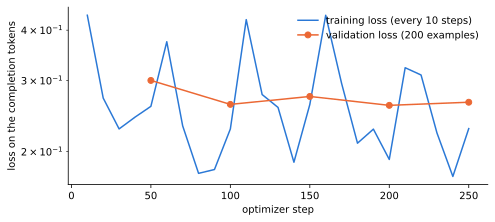

 step  eval_loss
   50   0.300348
  100   0.262009
  150   0.274125
  200   0.260576
  250   0.265231


In [16]:
log = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(figsize=(7, 3.2))
tr = log.dropna(subset=["loss"])
ev = log.dropna(subset=["eval_loss"])
ax.plot(tr["step"], tr["loss"], color="#2a78d6", label="training loss (every 10 steps)")
ax.plot(ev["step"], ev["eval_loss"], "o-", color="#eb6834", label=f"validation loss ({N_VAL} examples)")
ax.set_xlabel("optimizer step")
ax.set_ylabel("loss on the completion tokens")
ax.set_yscale("log")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(ev[["step", "eval_loss"]].to_string(index=False))

## 6. What changed?

Save the adapter, free the training model, and load the saved adapter on a fresh copy of the base model, as in
lesson 4: that scores exactly what was saved. The same 500 prompts are generated again and scored by the same checker.

In [17]:
trainer.model.save_pretrained("adapter")
adapter_mb = sum(os.path.getsize(os.path.join("adapter", f)) for f in os.listdir("adapter")) / 1e6
print(f"adapter on disk: {adapter_mb:.1f} MB; trainable parameters: {n_trainable:,} = {n_trainable / (n_all - n_trainable):.2%} of the base weights")
del trainer, model
gc.collect()
torch.cuda.empty_cache()

tuned = PeftModel.from_pretrained(
    AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE}), "adapter").eval()
answers, speed["fine-tuned"] = generate(tuned, [r["prompt"] for r in test])
scored["fine-tuned"] = score(test, answers)
for k, v in summary(scored["fine-tuned"]).items():
    print(f"{k:28s} {v:6.1%}")
print(f"\n{speed['fine-tuned']:.0f} ms per example (adapter not merged)")

adapter on disk: 73.9 MB; trainable parameters: 18,464,768 = 1.20% of the base weights


call: parse                   91.7%
call: name                    91.7%
call: schema                  91.3%
call: exact                   81.7%
no call: missing value        96.2%
no call: no fit              100.0%
no call: unrelated tools     100.0%
all 500: passed               88.4%

576 ms per example (adapter not merged)


In [18]:
n_by = {"call": TEST_MIX["call"], **{f"no call: {k}": TEST_MIX[k] for k in ["missing value", "no fit", "unrelated tools"]}, "all 500: passed": N_TEST}
base_s, tuned_s = summary(scored["baseline"]), summary(scored["fine-tuned"])
table = pd.DataFrame({"baseline %": base_s, "fine-tuned %": tuned_s}) * 100
table["± (95%, fine-tuned)"] = [100 * ci(tuned_s[k], n_by["call"] if k.startswith("call") else n_by[k]) for k in tuned_s]
table["change, points"] = table["fine-tuned %"] - table["baseline %"]
print(table.round(1).to_string())
print(f"\ntraining: {N_TRAIN:,} examples, {train_secs / 60:.0f} minutes, peak {peak_alloc:.1f} GB, adapter {adapter_mb:.0f} MB")
both = scored["baseline"]["ok"] & scored["fine-tuned"]["ok"]
print(f"\npassed by both: {both.sum()} | fixed by training: {(~scored['baseline']['ok'] & scored['fine-tuned']['ok']).sum()}"
      f" | broken by training: {(scored['baseline']['ok'] & ~scored['fine-tuned']['ok']).sum()} | failed by both: "
      f"{(~scored['baseline']['ok'] & ~scored['fine-tuned']['ok']).sum()}")
json.dump({"table": table.round(2).to_dict(), "train_minutes": train_secs / 60, "peak_alloc_gb": peak_alloc, "adapter_mb": adapter_mb,
           "ms_per_example": speed, "counts": {"train": N_TRAIN, "val": N_VAL, "test": N_TEST}}, open("results.json", "w"), indent=1)

                          baseline %  fine-tuned %  ± (95%, fine-tuned)  change, points
call: parse                    100.0          91.7                  3.1            -8.3
call: name                     100.0          91.7                  3.1            -8.3
call: schema                    99.7          91.3                  3.2            -8.3
call: exact                     75.7          81.7                  4.4             6.0
no call: missing value          88.8          96.2                  4.2             7.5
no call: no fit                 98.3         100.0                  0.0             1.7
no call: unrelated tools        73.3         100.0                  0.0            26.7
all 500: passed                 80.2          88.4                  2.8             8.2

training: 4,000 examples, 21 minutes, peak 7.3 GB, adapter 74 MB

passed by both: 392 | fixed by training: 50 | broken by training: 9 | failed by both: 49


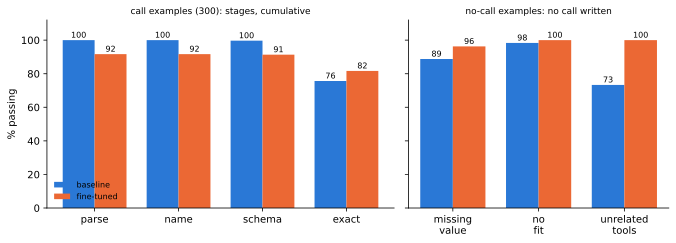

In [19]:
# One chart: the pass rate at each stage of the checker, before and after training; and the no-call kinds beside it.
labels = ["parse", "name", "schema", "exact"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.5), gridspec_kw={"width_ratios": [4, 3]}, sharey=True)
x = np.arange(4)
w = 0.38
for ax, keys, names, title in [(a1, [f"call: {s}" for s in labels], labels, f"call examples ({TEST_MIX['call']}): stages, cumulative"),
                               (a2, ["no call: missing value", "no call: no fit", "no call: unrelated tools"],
                                ["missing\nvalue", "no\nfit", "unrelated\ntools"], "no-call examples: no call written")]:
    xs = np.arange(len(keys))
    b = [base_s[k] * 100 for k in keys]
    t = [tuned_s[k] * 100 for k in keys]
    ax.bar(xs - w / 2, b, w, color="#2a78d6", label="baseline")
    ax.bar(xs + w / 2, t, w, color="#eb6834", label="fine-tuned")
    for i, (u, v) in enumerate(zip(b, t)):
        ax.text(i - w / 2, u + 1.5, f"{u:.0f}", ha="center", fontsize=8)
        ax.text(i + w / 2, v + 1.5, f"{v:.0f}", ha="center", fontsize=8)
    ax.set_xticks(xs)
    ax.set_xticklabels(names)
    ax.set_title(title, fontsize=9)
    ax.set_ylim(0, 112)
    ax.spines[["top", "right"]].set_visible(False)
a1.set_ylabel("% passing")
a1.legend(frameon=False, loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

## 7. What is still wrong?

The checker already says *where* each output failed. This table counts the first failing stage for every
output that did not pass, before and after training. The same words are used for call and no-call examples, so a row such
as "no call (answered in text)" is a call example the model answered in prose, and "called a function" is a no-call
example where it called one.

In [20]:
def failures(df):
    bad = df[~df["ok"]]
    return bad.groupby([bad["kind"].eq("call").map({True: "call example", False: "no-call example"}), "failure"]).size()


fail_table = pd.DataFrame({"baseline": failures(scored["baseline"]), "fine-tuned": failures(scored["fine-tuned"])}).fillna(0).astype(int)
print(fail_table.to_string())
print("\nfailures in total:", fail_table.sum().to_dict())

                                              baseline  fine-tuned
kind            failure                                           
call example    missing required argument            1           1
                no call (answered in text)           0          25
                valid arguments, wrong value        72          29
no-call example called a function                   26           3

failures in total: {'baseline': 99, 'fine-tuned': 58}


In [21]:
final = scored["fine-tuned"]
shown = pd.concat([final[(final["kind"] == "call") & ~final["ok"]].sample(frac=1, random_state=SEED).head(4),
                   final[(final["kind"] != "call") & ~final["ok"]].sample(frac=1, random_state=SEED).head(2)])
for i, row in shown.iterrows():
    print(f"[{row['failure']}]  ({row['kind']})")
    print("  request:", test[i]["user"][:130].replace("\n", " "))
    print("  offered:", [t["function"]["name"] for t in test[i]["tools"]])
    print("  gold   :", json.dumps(test[i]["gold"]) if test[i]["gold"] else "(no call)")
    print("  model  :", row["output"][:220].replace("\n", " "), "\n")

[no call (answered in text)]  (call)
  request: I need to create an invoice for my customer, John Doe. The total amount is $500.
  offered: ['create_invoice', 'get_daily_news']
  gold   : {"name": "create_invoice", "arguments": {"customer": "John Doe", "amount": 500}}
  model  : Sure, I can help with that. Could you please provide me with your email address so we can send the invoice? 

[no call (answered in text)]  (call)
  request: I'm looking for a movie but I can't remember the title. I know Leonardo DiCaprio was in it.
  offered: ['search_movie']
  gold   : {"name": "search_movie", "arguments": {"query": "Leonardo DiCaprio"}}
  model  : Sure, I can help with that. Do you have any other details about the movie? For example, did you see it recently or does it fall under a specific genre? 

[no call (answered in text)]  (call)
  request: Hi, I'm looking for a movie but I can't remember the full title. I know it was a comedy released in 2005.
  offered: ['search_movie']
  gold   : {"n

Some of the "valid arguments, wrong value" failures may not be errors: the gold target sometimes has an empty string
or an invented default for a value the user never gave (the data was written by a language model, not by a user of
a real API). The exact stage is strict by design, so it counts those as misses. The other three stages do not
depend on the gold values.

## 8. What do we keep?

The adapter was saved to `./adapter` in section 6, and section 6 scored it after loading it back, so the saved files
are the ones measured. It holds only the LoRA matrices and their configuration; it is loaded on top of the original
Qwen2.5-1.5B-Instruct, and the prompts must be built the same way (`tools=` in the chat template, the same system line).
In Colab, download it from the Files panel on the left. `results.json` holds the table above.

In [22]:
for f in sorted(os.listdir("adapter")):
    print(f"{os.path.getsize(os.path.join('adapter', f)) / 1e6:8.2f} MB  {f}")
print(json.load(open("adapter/adapter_config.json"))["base_model_name_or_path"])

    0.01 MB  README.md
    0.00 MB  adapter_config.json
   73.91 MB  adapter_model.safetensors
Qwen/Qwen2.5-1.5B-Instruct


## Read the result

- **A program was the judge.** Three of the four stages need no gold answer, only the function list, so the same checker
  could run on live traffic as a guard: reject a call that does not parse or does not fit the schema, before it
  reaches an API.
- **Read the stages, not only the total.** The drop between two stages names the weakness: between parse and name,
  the model calls the wrong or an invented function; between name and schema, it breaks the function's own rules;
  between schema and exact, it picks the wrong value.
- **Not calling is part of the task.** Compare the no-call rows with the call rows: a model tuned to call
  more must not lose the ability to stay silent. The table says whether it did.
- **The test used functions the model never saw in training,** which is what a deployed assistant meets when a new
  tool is added. A random split would have measured recall of functions seen in training.
- **The data narrows the claim.** One call per answer, one user turn, labels written by a language model: the results
  say nothing about several calls in a row, tool results fed back, or real users.

The lesson explains each result and the companies that learned the same lessons:
[Tool calls for agents](https://docs.recohut.com/courses/llm-fine-tuning/2-train/06-tool-calls).